# K-means

### Introducción

**K-means** es un algoritmo de aprendizaje no supervisado que permite agrupar datos con características similares en conjuntos llamados *clusters*. Para ello, utiliza centroides y calcula la distancia entre las observaciones para determinar a qué grupo pertenecen.

En esta práctica utilizaremos K-means para analizar el comportamiento de jugadores en tres escenarios: **economía del juego, detección de hackers y estilos de batalla**. A partir de sus métricas, buscaremos identificar agrupaciones y evaluar qué cantidad de clusters representa mejor los datos.

In [1]:
# python 
import os
os.environ["OMP_NUM_THREADS"] = "3"
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt



df = pd.read_csv("./datasets/comportamiento_jugadores.csv")
df.head(100)


Matplotlib is building the font cache; this may take a moment.


,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
...,...,...,...,...
95,49.823761,136.865158,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
96,35.114618,121.159379,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
97,22.449715,102.720996,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
98,22.435696,114.961632,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD


### 2. Filtrado y estandarización de datos

Primero separamos los datos en tres conjuntos según su escenario y seleccionamos las variables `Metrica_X` y `Metrica_Y`.

Después utilizamos **StandardScaler** para estandarizar los valores, evitando que una variable tenga mayor influencia debido a su escala.

La estandarización se realiza mediante:

$$
z = \frac{x-\mu}{\sigma}
$$

Donde $x$ es el valor original, $\mu$ es la media y $\sigma$ es la desviación estándar.

In [2]:
# Filtrado
df_1_Economia_Juego = df[df["Escenario"] == "1_Economia_Juego"]
df_2_Deteccion_Hackers = df[df["Escenario"] == "2_Deteccion_Hackers"]
df_3_Estilos_Batalla = df[df["Escenario"] == "3_Estilos_Batalla"]

# Verification
# print("------------\n",df_1_Economia_Juego.head(5))
# print("------------\n",df_2_Deteccion_Hackers.head(5))
# print("------------\n",df_3_Estilos_Batalla.head(5))

# Extraer métricas
df_1_Economia_Juego_raw = df_1_Economia_Juego[["Metrica_X","Metrica_Y"]]
df_2_Deteccion_Hackers_raw = df_2_Deteccion_Hackers[["Metrica_X","Metrica_Y"]]
df_3_Estilos_Batalla_raw = df_3_Estilos_Batalla[["Metrica_X","Metrica_Y"]]

scaler_1, scaler_2, scaler_3 = StandardScaler(), StandardScaler(), StandardScaler()

# Escalamiento
df_1_scaled = scaler_1.fit_transform(df_1_Economia_Juego_raw)
df_2_scaled = scaler_2.fit_transform(df_2_Deteccion_Hackers_raw)
df_3_scaled = scaler_3.fit_transform(df_3_Estilos_Batalla_raw)

### 3. Selección del número de clusters

En esta sección probamos diferentes valores de **K (de 2 a 8)** para identificar la cantidad de clusters más adecuada.
K-means funciona mediante dos operaciones principales:

1. **Asignación:** cada observación se asigna al centroide más cercano, utilizando la distancia euclidiana:

   $$
   d(x,c)=\sqrt{\sum_{j=1}^{n}(x_j-c_j)^2}
   $$

2. **Actualización:** cada centroide se recalcula como el promedio de los puntos asignados a su cluster:

   $$
   c_k=\frac{1}{N_k}\sum_{i=1}^{N_k}x_i
   $$

Este proceso se repite hasta que los centroides se estabilizan o se alcanza el límite de iteraciones.

Para evaluar los resultados utilizamos:

- **Inercia:** mide qué tan compactos son los clusters mediante la suma de distancias cuadradas.
- **Silhouette Score:** mide qué tan bien agrupados y separados están los datos. Un valor cercano a 1 indica una mejor separación.

Estas métricas nos permiten comparar diferentes valores de K y seleccionar el más adecuado.

In [3]:
# Selección del numero de clusters

# Posible rango de clusters
range_n_clusters = range(2, 9)
datasets = {
    "df_Economia_Juego_Scaled": df_1_scaled, 
    "df_Deteccion_Hackers_Scaled": df_2_scaled,
    "df_Estilos_Batalla_Scaled": df_3_scaled
}

''' 
Aqui a lo mejor podrían hacer una grafica como las que tiene aca
https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html#sphx-glr-auto-examples-cluster-plot-kmeans-silhouette-analysis-py
'''

resultados = []
for nombre, datos in datasets.items():
    for i in range_n_clusters:
        # Inicilialización del clusterer con n_clusters
        clusterer = KMeans(n_clusters=i, random_state=10, n_init=10)
        cluster_labels = clusterer.fit_predict(datos)

        # El silhouette_score nos da el promedio para todas las muestras
        # Nos ayuda a visualizar la densidad y separación de los clusters creados
        silhouette_avg = silhouette_score(datos, cluster_labels)

        resultados.append({
            "dataset": nombre,
            "n_clusters": i,
            "inercia": clusterer.inertia_,
            "silhouette": silhouette_avg
        })

df_resultados = pd.DataFrame(resultados)
print(df_resultados)
print(
    df_resultados.sort_values("silhouette", ascending=False)
    .groupby("dataset").head(1).sort_values("dataset")
)

                        dataset  n_clusters     inercia  silhouette
0      df_Economia_Juego_Scaled           2  309.952133    0.678296
1      df_Economia_Juego_Scaled           3   71.873618    0.737604
2      df_Economia_Juego_Scaled           4   62.534017    0.604248
3      df_Economia_Juego_Scaled           5   53.877370    0.484153
4      df_Economia_Juego_Scaled           6   46.892207    0.322082
5      df_Economia_Juego_Scaled           7   40.581802    0.340328
6      df_Economia_Juego_Scaled           8   35.126389    0.347349
7   df_Deteccion_Hackers_Scaled           2  502.641571    0.494194
8   df_Deteccion_Hackers_Scaled           3  369.783088    0.442570
9   df_Deteccion_Hackers_Scaled           4  245.653731    0.437400
10  df_Deteccion_Hackers_Scaled           5  181.050728    0.463206
11  df_Deteccion_Hackers_Scaled           6  138.036082    0.476758
12  df_Deteccion_Hackers_Scaled           7  109.674004    0.495977
13  df_Deteccion_Hackers_Scaled           8   84

### Resultados obtenidos

Al evaluar los diferentes valores de K, encontramos los siguientes resultados con base en el mayor **Silhouette Score**:

| Escenario | Mejor K | Silhouette Score |
|---|---|---|
| Economía del juego | 3 | 0.7376 |
| Detección de hackers | 7 | 0.4960 |
| Estilos de batalla | 7 | 0.5292 |

El escenario de **economía del juego** obtuvo la mejor separación entre grupos, mientras que los otros dos presentaron una separación moderada.

Estos resultados permiten seleccionar el número de clusters más adecuado para cada escenario según el Silhouette Score.

### 4. Entrenamiento de los modelos K-means

Aplicamos K-means a los tres conjuntos de datos estandarizados, utilizando los valores de K seleccionados mediante el **Silhouette Score**:

- **Economía del juego:** 3 clusters.
- **Detección de hackers:** 7 clusters.
- **Estilos de batalla:** 7 clusters.

La función `fit_predict()` entrena cada modelo y asigna a cada observación una etiqueta que identifica el cluster al que pertenece.

De esta manera, agrupamos a los jugadores según la similitud de sus características.

In [4]:
# Modelos
km_economia_juego = KMeans(n_clusters=3, random_state=10, n_init=10).fit_predict(df_1_scaled)
km_deteccion_hackers = KMeans(n_clusters=7, random_state=10, n_init=10).fit_predict(df_2_scaled)
km_estilos_batalla = KMeans(n_clusters=7, random_state=10, n_init=10).fit_predict(df_3_scaled)

### 5. Visualización de los clusters

En esta sección utilizamos **Matplotlib** para visualizar los clusters generados por K-means en cada escenario.

Cada punto representa un jugador y su color indica el cluster al que pertenece. Las gráficas utilizan las métricas originales para facilitar la interpretación de los resultados.

Estas visualizaciones permiten observar cómo se distribuyen los jugadores y distinguir los grupos identificados por el algoritmo.

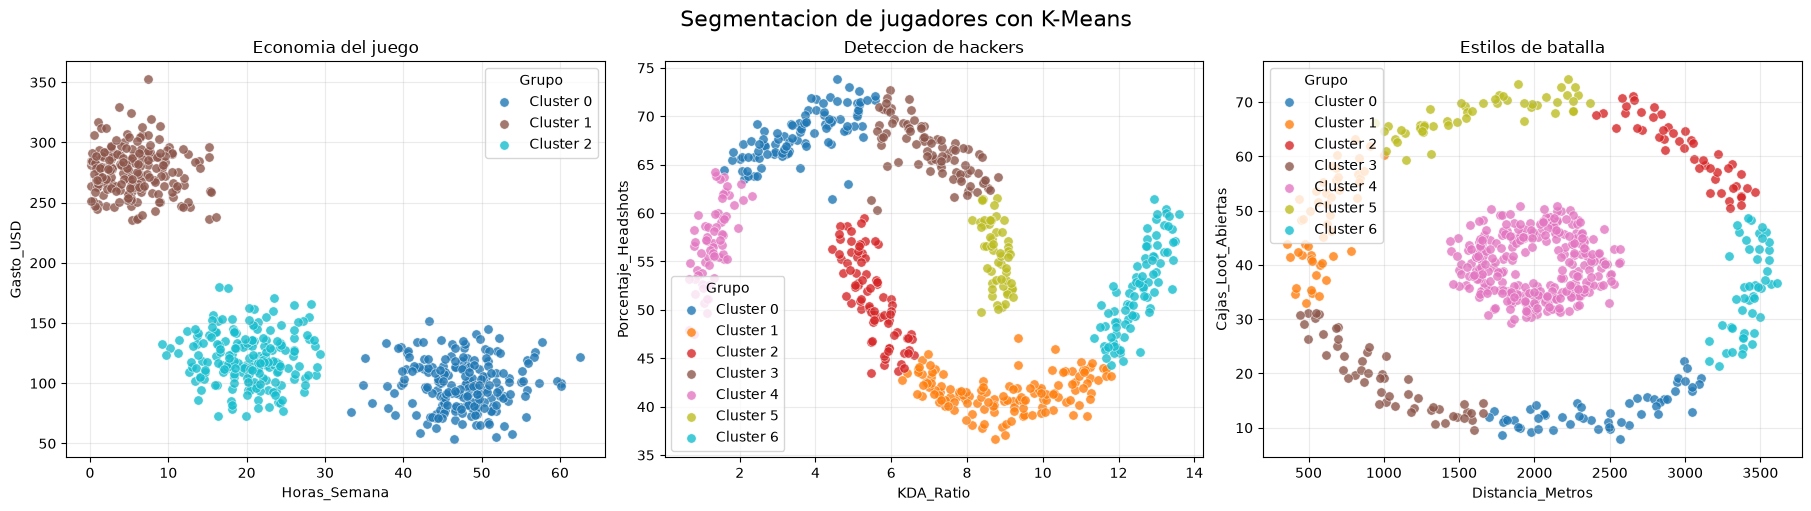

In [5]:
# Visualizacion de los clusters en las metricas originales
escenarios = [
    (df_1_Economia_Juego, km_economia_juego, "Economia del juego"),
    (df_2_Deteccion_Hackers, km_deteccion_hackers, "Deteccion de hackers"),
    (df_3_Estilos_Batalla, km_estilos_batalla, "Estilos de batalla"),
]

fig, axes = plt.subplots(1, len(escenarios), figsize=(18, 5), constrained_layout=True)

for ax, (datos, etiquetas, titulo) in zip(axes, escenarios):
    descripcion_ejes = datos["Descripcion_Ejes"].iloc[0].split("|")
    nombre_eje_x = descripcion_ejes[0].replace("X:", "").strip()
    nombre_eje_y = descripcion_ejes[1].replace("Y:", "").strip()
    colores = plt.get_cmap("tab10", len(np.unique(etiquetas)))

    for indice, cluster in enumerate(np.unique(etiquetas)):
        seleccion = etiquetas == cluster
        ax.scatter(
            datos["Metrica_X"].to_numpy()[seleccion],
            datos["Metrica_Y"].to_numpy()[seleccion],
            color=colores(indice),
            label=f"Cluster {cluster}",
            s=45,
            alpha=0.8,
            edgecolors="white",
            linewidths=0.4,
        )

    ax.set_title(titulo)
    ax.set_xlabel(nombre_eje_x)
    ax.set_ylabel(nombre_eje_y)
    ax.grid(True, alpha=0.25)
    ax.legend(title="Grupo", loc="best")

fig.suptitle("Segmentacion de jugadores con K-Means", fontsize=16)
plt.show()